In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

In [5]:
synthetic_train = pd.read_csv('anthrax_decision_support_data.csv')
synthetic_train.head()

,Fever,Convulsions,Resp_Cardiac_Distress,Rumination Cessation,Milk Production Loss,Abortion,Bloody_Discharge,Edema,Reduced_Appetite,Lethargy,Staggering,Somnolence,Recumbence,Trembling,Anthrax
0,0,0,0,1,1,1,1,0,0,1,0,1,0,1,0
1,1,0,0,1,1,0,0,1,0,1,0,1,0,1,1
2,1,0,1,1,1,0,0,0,1,0,1,0,0,0,1
3,1,0,1,1,1,0,1,1,0,1,0,0,0,1,1
4,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0


In [6]:
synthetic_train = synthetic_train.drop_duplicates()

In [7]:
field_test = pd.read_csv("Anthrax field data updated.csv")
field_test.head(3)

,Fever,Convulsions,Resp_Cardiac_Distress,Rumination Cessation,Milk Production Loss,Abortion,Bloody_Discharge,Edema,Reduced_Appetite,Lethargy,Staggering,Somnolence,Recumbence,Trembling,Anthrax
0,1,1,0,1,1,0,0,0,1,0,1,0,1,1,1
1,1,1,1,1,0,0,0,0,1,0,1,0,0,1,1
2,1,1,0,1,1,1,1,1,0,0,1,0,1,1,1


In [8]:
synthetic_train[synthetic_train.columns] = synthetic_train[synthetic_train.columns].astype('float64')

In [9]:
field_test[field_test.columns] = field_test[field_test.columns].astype('float64')

In [10]:
x = synthetic_train.iloc[: , [0,1,2,3,4,5,6,7,8,9,10,11,12,13]]
y = synthetic_train.iloc[: , -1]

In [11]:
x_test = field_test.iloc[: , [0,1,2,3,4,5,6,7,8,9,10,11,12,13]]
y_test = field_test.iloc[: , -1]

In [12]:
from sklearn.model_selection import train_test_split

x_train, x_dev, y_train, y_dev = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters Found: {'classifier__C': np.float64(1.9340450985343383), 'classifier__class_weight': 'balanced', 'classifier__gamma': 'auto', 'classifier__kernel': 'rbf'}
Best Cross-Validation Roc-AUC: 0.9732696078431372

In [16]:
from sklearn.svm import SVC

svm = SVC(
    C = 1.93,
    class_weight= "balanced",
    gamma = "auto",
    kernel = "rbf",
    probability=True,
    random_state=42
)

In [17]:
svm.fit(x_train, y_train)

SVC(C=1.93, class_weight='balanced', gamma='auto', probability=True,
    random_state=42)

In [21]:
y_prob = svm.predict_proba(x_test)[:, 1]

In [22]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

         0.0       1.00      0.61      0.76        31
         1.0       0.60      1.00      0.75        18

    accuracy                           0.76        49
   macro avg       0.80      0.81      0.76        49
weighted avg       0.85      0.76      0.76        49

[[19 12]
 [ 0 18]]


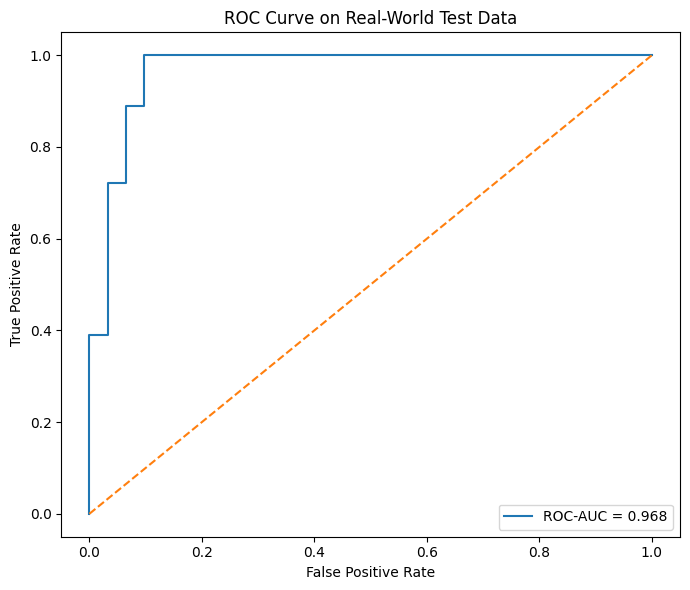

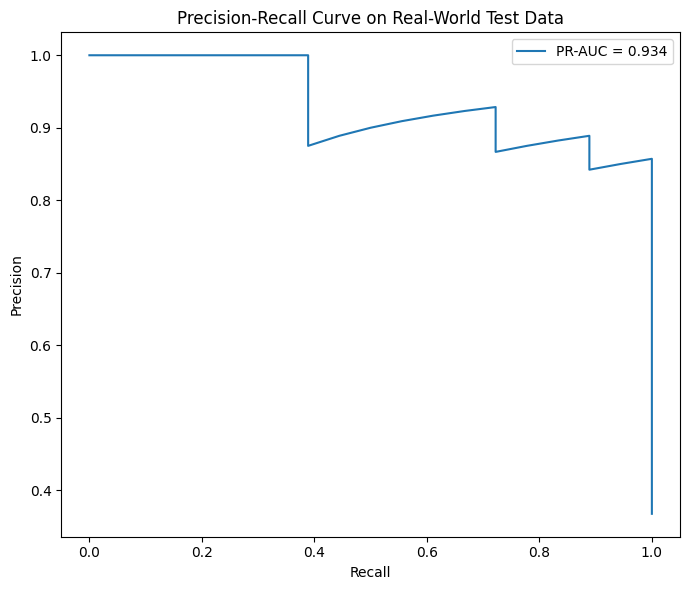

ROC-AUC: 0.968
PR-AUC:  0.934


In [23]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# Predicted probabilities on real-world test data
y_prob_real = svm.predict_proba(x_test)[:, 1]

# =========================
# ROC-AUC
# =========================
fpr, tpr, _ = roc_curve(y_test, y_prob_real)
roc_auc = roc_auc_score(y_test, y_prob_real)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve on Real-World Test Data")
plt.legend()
plt.tight_layout()
plt.show()


# =========================
# PR-AUC
# =========================
precision, recall, _ = precision_recall_curve(y_test, y_prob_real)
pr_auc = average_precision_score(y_test, y_prob_real)

plt.figure(figsize=(7, 6))
plt.plot(recall, precision, label=f"PR-AUC = {pr_auc:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve on Real-World Test Data")
plt.legend()
plt.tight_layout()
plt.show()

print(f"ROC-AUC: {roc_auc:.3f}")
print(f"PR-AUC:  {pr_auc:.3f}")

Using 659 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


  0%|          | 0/49 [00:00<?, ?it/s]

<Figure size 640x480 with 0 Axes>

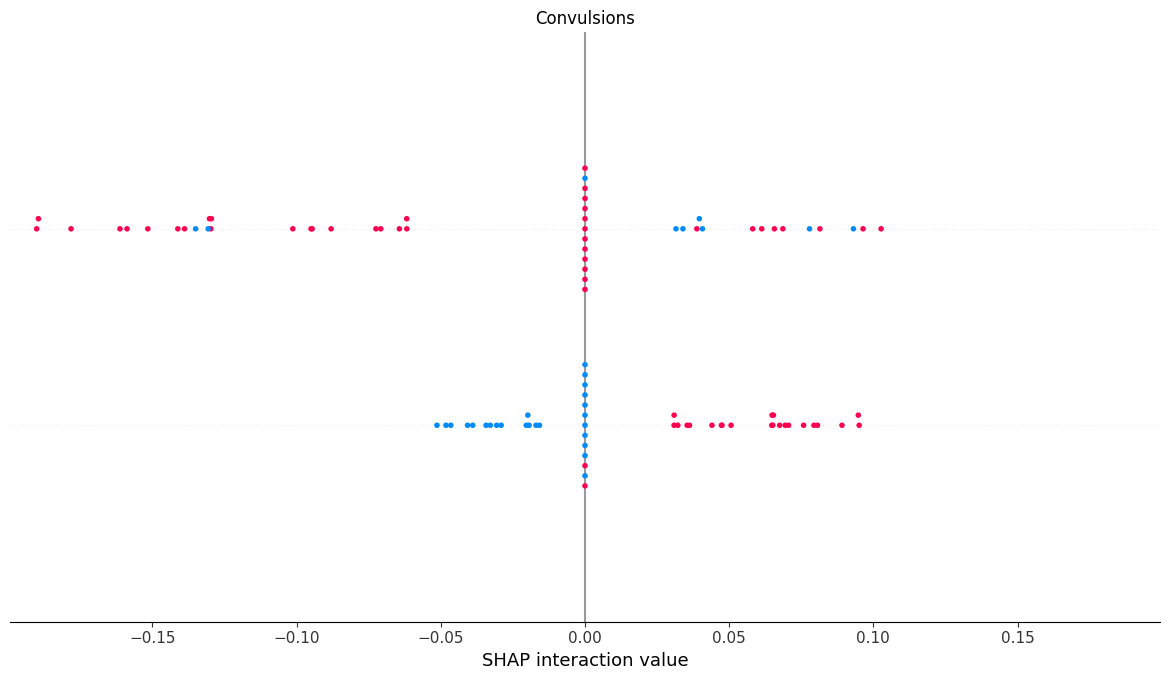

In [28]:
import shap

explainer = shap.KernelExplainer(
    svm.predict_proba,
    x_train
)

shap_values = explainer.shap_values(x_test)

# Binary classification → class 1
if isinstance(shap_values, list):
    shap_values = shap_values[1]

shap.summary_plot(
    shap_values,
    x_test,
    plot_type="bar"
)

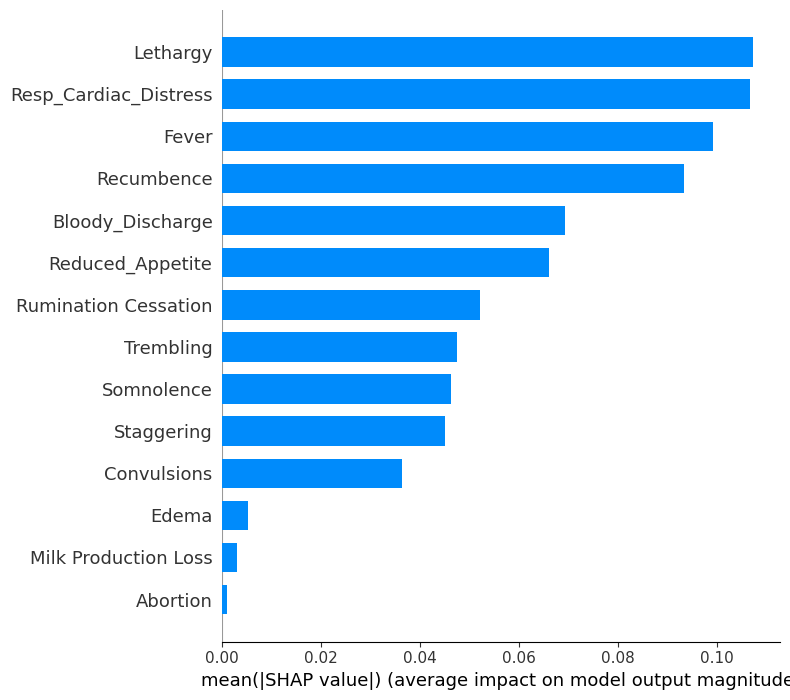

In [29]:
# Handle different SHAP output formats
if isinstance(shap_values, list):
    shap_values = shap_values[1]          # class 1
elif shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]    # class 1

shap.summary_plot(
    shap_values,
    x_test,
    plot_type="bar"
)

In [2]:
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

pipeline = Pipeline([
    ('classifier', SVC(random_state=42, probability=True))
])

In [13]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import uniform

param_dist = {
    'classifier__C': uniform(0.1, 10),
    'classifier__kernel': ['linear', 'rbf'],
    'classifier__gamma': ['scale', 'auto'],
    'classifier__class_weight': [None, 'balanced']
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_dist,
    n_iter=20,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=2,
    random_state=42,
    return_train_score=True
)

random_search.fit(x, y)

print("Best Parameters Found:", random_search.best_params_)
print("Best Cross-Validation Roc-AUC:", random_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters Found: {'classifier__C': np.float64(1.9340450985343383), 'classifier__class_weight': 'balanced', 'classifier__gamma': 'auto', 'classifier__kernel': 'rbf'}
Best Cross-Validation Roc-AUC: 0.9732696078431372
